# **Import Libraries**

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# **Load Data**

In [28]:
df = pd.read_csv('HR_Attrition_Indian_Dataset.csv')
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (5000, 22)


,EmployeeID,FullName,Age,Gender,Department,Designation,EducationQualification,MonthlySalary,DateOfJoining,YearsWithCompany,...,TrainingHours,DoesOvertime,JobSatisfaction,WorkLifeBalance,MaritalStatus,PreviousCompanies,DistanceFromHome,LeavesTaken,City,LeftCompany
0,EMP20230001,Sahil Tailor,48,Other,HR,Accounts Officer,B.Tech,111813,2020-05-26,5,...,37,Yes,4,3,Single,0,12.2,4,Mumbai,No
1,EMP20230002,Parinaaz Choudhary,26,Female,IT,Accounts Officer,B.Tech,87425,2020-10-02,5,...,39,No,2,2,Divorced,0,36.7,29,Kolkata,No
2,EMP20230003,Anahi Babu,40,Male,IT,Software Engineer,Diploma,86461,2021-05-01,4,...,32,No,2,3,Married,1,45.4,0,Bengaluru,Yes
3,EMP20230004,Dhruv Dass,54,Other,HR,Accounts Officer,Diploma,23720,2023-04-01,2,...,21,Yes,4,4,Married,0,29.9,27,Kolkata,No
4,EMP20230005,Seher Bal,51,Other,Admin,Sales Associate,B.Tech,39041,2018-12-19,7,...,30,No,2,2,Single,0,26.8,6,Delhi,Yes


In [17]:
df.describe()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   EmployeeID              5000 non-null   object 
 1   FullName                5000 non-null   object 
 2   Age                     5000 non-null   int64  
 3   Gender                  5000 non-null   object 
 4   Department              5000 non-null   object 
 5   Designation             5000 non-null   object 
 6   EducationQualification  5000 non-null   object 
 7   MonthlySalary           5000 non-null   int64  
 8   DateOfJoining           5000 non-null   object 
 9   YearsWithCompany        5000 non-null   int64  
 10  YearsInRole             5000 non-null   int64  
 11  AppraisalRating         5000 non-null   int64  
 12  TrainingHours           5000 non-null   int64  
 13  DoesOvertime            5000 non-null   object 
 14  JobSatisfaction         5000 non-null   

# **Data Quality Checks**

In [18]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate EmployeeIDs:", df['EmployeeID'].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())

Total missing values: 0
Duplicate EmployeeIDs: 0
Duplicate rows: 0


# **Create Attrition Flag**

In [19]:
df['AttritionFlag'] = df['LeftCompany'].eq('Yes').astype(int)

overall_rate = df['AttritionFlag'].mean() * 100
print(f"Overall attrition rate: {overall_rate:.1f}%")
print(df['LeftCompany'].value_counts())

Overall attrition rate: 37.1%
LeftCompany
No     3145
Yes    1855
Name: count, dtype: int64


# **Function**

In [20]:
def analyze_attrition(data, group_column, sort_by_rate=True):
    result = (
        data.groupby(group_column, observed=True)
        .agg(
            Employee_Count=('EmployeeID', 'count'),
            Employees_Left=('AttritionFlag', 'sum'),
            Attrition_Rate=('AttritionFlag', 'mean')
        )
    )
    result['Attrition_Rate'] = (result['Attrition_Rate'] * 100).round(2)
    if sort_by_rate:
        result = result.sort_values('Attrition_Rate', ascending=False)
    return result

# **Factors**

In [21]:
for col in ['Department', 'Designation', 'City', 'Gender', 'MaritalStatus', 'EducationQualification']:
    print(f"\n===== {col} =====")
    print(analyze_attrition(df, col))


===== Department =====
            Employee_Count  Employees_Left  Attrition_Rate
Department                                                
Sales                 1019             391           38.37
IT                     983             373           37.95
Admin                  975             360           36.92
Accounts              1031             374           36.28
HR                     992             357           35.99

===== Designation =====
                   Employee_Count  Employees_Left  Attrition_Rate
Designation                                                      
Accounts Officer             1008             388           38.49
Office Assistant              993             376           37.87
HR Executive                 1049             391           37.27
Software Engineer             995             363           36.48
Sales Associate               955             337           35.29

===== City =====
           Employee_Count  Employees_Left  Attrition_Rate


# **Group Numbers into Bands**

In [22]:
df['SalaryBand'] = pd.cut(
    df['MonthlySalary'],
    bins=[0, 35000, 55000, 75000, 95000, float('inf')],
    labels=['Entry', 'Lower-Mid', 'Mid', 'Upper-Mid', 'High'],
    right=False
)

df['TenureBand'] = pd.cut(
    df['YearsWithCompany'],
    bins=[0, 2, 4, 7, 10],
    labels=['1-2 yrs', '3-4 yrs', '5-7 yrs', '8-10 yrs']
)

df['Appraisal_Group'] = pd.cut(
    df['AppraisalRating'], [0, 2, 3, 5],
    labels=['Low (1-2)', 'Average (3)', 'High (4-5)']
)

df['Satisfaction_Group'] = pd.cut(
    df['JobSatisfaction'], [0, 2, 3, 5],
    labels=['Low (1-2)', 'Moderate (3)', 'High (4-5)']
)

df['WLB_Group'] = pd.cut(
    df['WorkLifeBalance'], [0, 1, 3, 4],
    labels=['Poor (1)', 'Moderate (2-3)', 'Good (4)']
)

df['PrevCompanies_Group'] = pd.cut(
    df['PreviousCompanies'], [-1, 0, 2, 4, 5],
    labels=['0', '1-2', '3-4', '5']
)

# **Attrition By Numeric Factors**

In [23]:
for col in ['DoesOvertime', 'Satisfaction_Group', 'WLB_Group', 'Appraisal_Group',
            'SalaryBand', 'TenureBand', 'PrevCompanies_Group']:
    print(f"\n===== {col} =====")
    print(analyze_attrition(df, col, sort_by_rate=False))


===== DoesOvertime =====
              Employee_Count  Employees_Left  Attrition_Rate
DoesOvertime                                                
No                      2539             782            30.8
Yes                     2461            1073            43.6

===== Satisfaction_Group =====
                    Employee_Count  Employees_Left  Attrition_Rate
Satisfaction_Group                                                
Low (1-2)                     1993            1026           51.48
Moderate (3)                  1010             269           26.63
High (4-5)                    1997             560           28.04

===== WLB_Group =====
                Employee_Count  Employees_Left  Attrition_Rate
WLB_Group                                                     
Poor (1)                  1246             676           54.25
Moderate (2-3)            2497             803           32.16
Good (4)                  1257             376           29.91

===== Appraisal_Group ==

# **Chart**

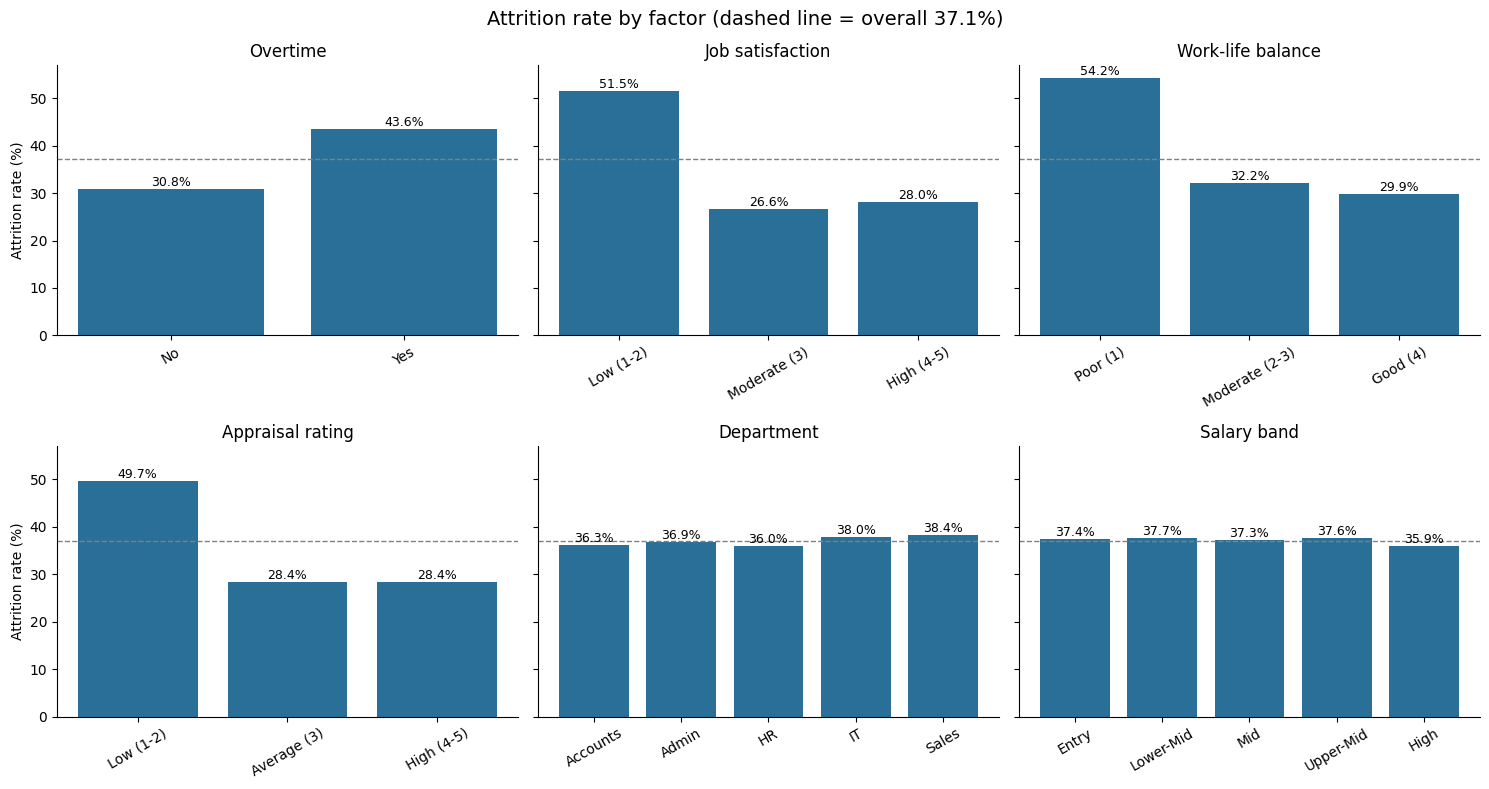

In [24]:
panels = [
    ('DoesOvertime', 'Overtime'),
    ('Satisfaction_Group', 'Job satisfaction'),
    ('WLB_Group', 'Work-life balance'),
    ('Appraisal_Group', 'Appraisal rating'),
    ('Department', 'Department'),
    ('SalaryBand', 'Salary band'),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, (col, title) in zip(axes.flat, panels):
    rates = analyze_attrition(df, col, sort_by_rate=False)['Attrition_Rate']
    bars = ax.bar(rates.index.astype(str), rates.values, color='#2a6f97')
    ax.bar_label(bars, fmt='%.1f%%', fontsize=9)
    ax.axhline(overall_rate, color='grey', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)
    ax.spines[['top', 'right']].set_visible(False)

axes[0, 0].set_ylabel('Attrition rate (%)')
axes[1, 0].set_ylabel('Attrition rate (%)')
fig.suptitle('Attrition rate by factor (dashed line = overall 37.1%)', fontsize=14)
plt.tight_layout()
plt.show()

# **Chi-Square Test**

In [25]:
def chi_test(col):
    table = pd.crosstab(df[col], df['LeftCompany'])
    chi2, p, dof, _ = chi2_contingency(table)
    cramers_v = (chi2 / (table.values.sum() * (min(table.shape) - 1))) ** 0.5
    return {'Factor': col, 'Chi-square': round(chi2, 1), 'p-value': p,
            "Cramer's V": round(cramers_v, 3),
            'Significant (p<0.05)': 'Yes' if p < 0.05 else 'No'}

factors = ['DoesOvertime', 'Satisfaction_Group', 'WLB_Group', 'Appraisal_Group',
           'PrevCompanies_Group', 'Department', 'Designation', 'Gender',
           'MaritalStatus', 'City', 'EducationQualification']

results = pd.DataFrame([chi_test(c) for c in factors])
results['p-value'] = results['p-value'].map(lambda x: f'{x:.2e}' if x < 0.001 else f'{x:.4f}')
results

,Factor,Chi-square,p-value,Cramer's V,Significant (p<0.05)
0,DoesOvertime,87.2,9.80e-21,0.132,Yes
1,Satisfaction_Group,294.2,1.28e-64,0.243,Yes
2,WLB_Group,211.1,1.47e-46,0.205,Yes
3,Appraisal_Group,234.3,1.35e-51,0.216,Yes
4,PrevCompanies_Group,10.6,0.0140,0.046,Yes
5,Department,1.8,0.7642,0.019,No
6,Designation,2.6,0.6258,0.023,No
7,Gender,0.8,0.6764,0.013,No
8,MaritalStatus,1.5,0.4637,0.018,No
9,City,0.9,0.9893,0.013,No


# **Combine Risk Factors**

              Employee_Count  Employees_Left  Attrition_Rate
risk_factors                                                
0                        665             124           18.65
1                       1831             402           21.96
2                       1714             685           39.96
3                        681             560           82.23
4                        109              84           77.06

Chi-square p-value (risk score vs attrition): 8.77e-205


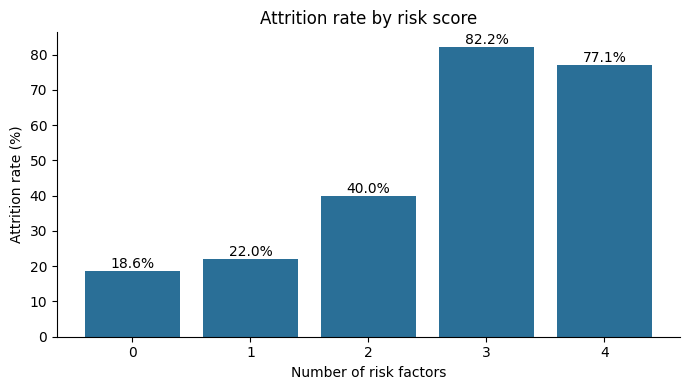

In [26]:
df['risk_factors'] = (
    (df['DoesOvertime'] == 'Yes').astype(int)
    + (df['JobSatisfaction'] <= 2).astype(int)
    + (df['WorkLifeBalance'] == 1).astype(int)
    + (df['AppraisalRating'] <= 2).astype(int)
)

risk = analyze_attrition(df, 'risk_factors', sort_by_rate=False)
print(risk)

_, p, _, _ = chi2_contingency(pd.crosstab(df['risk_factors'], df['LeftCompany']))
print(f"\nChi-square p-value (risk score vs attrition): {p:.2e}")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(risk.index.astype(str), risk['Attrition_Rate'], color='#2a6f97')
ax.bar_label(bars, fmt='%.1f%%')
ax.set_xlabel('Number of risk factors')
ax.set_ylabel('Attrition rate (%)')
ax.set_title('Attrition rate by risk score')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [27]:
high = df[df['risk_factors'] >= 3]
zero = df[df['risk_factors'] == 0]

print(f"Employees with 3+ risk factors: {len(high)} ({len(high) / len(df) * 100:.1f}% of workforce)")
print(f"Attrition rate, 3+ risk factors: {high['AttritionFlag'].mean() * 100:.1f}%")
print(f"Attrition rate, 0 risk factors:  {zero['AttritionFlag'].mean() * 100:.1f}%")

Employees with 3+ risk factors: 790 (15.8% of workforce)
Attrition rate, 3+ risk factors: 81.5%
Attrition rate, 0 risk factors:  18.6%
